# EDA Vehicle Types Density CH

## Bibliotheken importieren

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Datensätze öffnen

In [2]:
antriebsarten_df = pd.read_csv('data/Antriebsarten_nach_Gemeinden.csv', sep=',', encoding='latin1')
einwohner_df = pd.read_csv('data/Einwohner_nach_Gemeinden.csv', sep=',', encoding='latin1')
geografische_kzh_df = pd.read_csv('data/Geographische_Kennzahlen.csv', sep=';')

## Datensätze öffnen

### Antriebsarten nach Gemeinden

In [3]:
antriebsarten_df.head()

,"Gemeinde,""Fahrzeuggruppe"",""Treibstoff"",""2010"",""2011"",""2012"",""2013"",""2014"",""2015"",""2016"",""2017"",""2018"",""2019"",""2020"",""2021"",""2022"",""2023"",""2024"""
0,"1 Aeugst am Albis,""Personenwagen"",""Benzin"",863..."
1,"1 Aeugst am Albis,""Personenwagen"",""Diesel"",175..."
2,"1 Aeugst am Albis,""Personenwagen"",""Benzin-elek..."
3,"1 Aeugst am Albis,""Personenwagen"",""Benzin-elek..."
4,"1 Aeugst am Albis,""Personenwagen"",""Diesel-elek..."


In [4]:
antriebsarten_df.shape

(164087, 1)

In [5]:
antriebsarten_df.columns

Index(['Gemeinde,"Fahrzeuggruppe","Treibstoff","2010","2011","2012","2013","2014","2015","2016","2017","2018","2019","2020","2021","2022","2023","2024"'], dtype='str')

#### CSV korrekt formatieren

In [6]:
antriebsarten_split = antriebsarten_df.iloc[:, 0].str.split(',', expand=True)
antriebsarten_split.shape

(164087, 18)

In [7]:
antriebsarten_split.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,1 Aeugst am Albis,"""Personenwagen""","""Benzin""",863,881,891,881,856,845,822,815,816,809,804,789,778,774,724
1,1 Aeugst am Albis,"""Personenwagen""","""Diesel""",175,204,229,250,276,288,306,316,318,326,329,321,311,292,287
2,1 Aeugst am Albis,"""Personenwagen""","""Benzin-elektrisch: Normal-Hybrid""",3,5,7,11,13,13,18,16,20,22,30,43,49,57,74
3,1 Aeugst am Albis,"""Personenwagen""","""Benzin-elektrisch: Plug-in-Hybrid""",0,0,0,0,0,0,1,2,7,7,12,20,23,26,29
4,1 Aeugst am Albis,"""Personenwagen""","""Diesel-elektrisch: Normal-Hybrid""",0,0,1,1,0,0,0,2,2,3,2,5,5,7,4


##### Spaltennamen setzen

In [8]:
spaltennamen = antriebsarten_df.columns[0].split(',')
antriebsarten_split.columns = spaltennamen
antriebsarten_split.columns

Index(['Gemeinde', '"Fahrzeuggruppe"', '"Treibstoff"', '"2010"', '"2011"',
       '"2012"', '"2013"', '"2014"', '"2015"', '"2016"', '"2017"', '"2018"',
       '"2019"', '"2020"', '"2021"', '"2022"', '"2023"', '"2024"'],
      dtype='str')

##### Anführungszeichen entfernen

In [9]:
antriebsarten_split.columns = antriebsarten_split.columns.str.strip('"')
antriebsarten_split['Fahrzeuggruppe'] = antriebsarten_split['Fahrzeuggruppe'].str.strip('"')
antriebsarten_split['Treibstoff'] = antriebsarten_split['Treibstoff'].str.strip('"')

In [10]:
antriebsarten_split.head()

,Gemeinde,Fahrzeuggruppe,Treibstoff,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,1 Aeugst am Albis,Personenwagen,Benzin,863,881,891,881,856,845,822,815,816,809,804,789,778,774,724
1,1 Aeugst am Albis,Personenwagen,Diesel,175,204,229,250,276,288,306,316,318,326,329,321,311,292,287
2,1 Aeugst am Albis,Personenwagen,Benzin-elektrisch: Normal-Hybrid,3,5,7,11,13,13,18,16,20,22,30,43,49,57,74
3,1 Aeugst am Albis,Personenwagen,Benzin-elektrisch: Plug-in-Hybrid,0,0,0,0,0,0,1,2,7,7,12,20,23,26,29
4,1 Aeugst am Albis,Personenwagen,Diesel-elektrisch: Normal-Hybrid,0,0,1,1,0,0,0,2,2,3,2,5,5,7,4


In [11]:
personenwagen = antriebsarten_split[antriebsarten_split['Fahrzeuggruppe'] == 'Personenwagen']
personenwagen['2024'].sum()

'...'

##### Datentypen anpassen

In [12]:
antriebsarten_split.dtypes

Gemeinde          str
Fahrzeuggruppe    str
Treibstoff        str
2010              str
2011              str
2012              str
2013              str
2014              str
2015              str
2016              str
2017              str
2018              str
2019              str
2020              str
2021              str
2022              str
2023              str
2024              str
dtype: object

In [13]:
antriebsarten_split = antriebsarten_split.astype({'Fahrzeuggruppe': 'category', 'Treibstoff': 'category'})

jahre = antriebsarten_split.columns[3:]
antriebsarten_split[jahre] = antriebsarten_split[jahre].astype(int)

antriebsarten_split.dtypes

Gemeinde               str
Fahrzeuggruppe    category
Treibstoff        category
2010                 int64
2011                 int64
2012                 int64
2013                 int64
2014                 int64
2015                 int64
2016                 int64
2017                 int64
2018                 int64
2019                 int64
2020                 int64
2021                 int64
2022                 int64
2023                 int64
2024                 int64
dtype: object

##### Gemeindenummer separieren

In [14]:
antriebsarten_split[['GDENR', 'Gemeindename']] = antriebsarten_split['Gemeinde'].str.split(' ', n=1, expand=True)
antriebsarten_split['GDENR'] = antriebsarten_split['GDENR'].astype(int)

antriebsarten_split = antriebsarten_split.drop(columns='Gemeinde')


In [15]:
antriebsarten_split.head()

,Fahrzeuggruppe,Treibstoff,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,GDENR,Gemeindename
0,Personenwagen,Benzin,863,881,891,881,856,845,822,815,816,809,804,789,778,774,724,1,Aeugst am Albis
1,Personenwagen,Diesel,175,204,229,250,276,288,306,316,318,326,329,321,311,292,287,1,Aeugst am Albis
2,Personenwagen,Benzin-elektrisch: Normal-Hybrid,3,5,7,11,13,13,18,16,20,22,30,43,49,57,74,1,Aeugst am Albis
3,Personenwagen,Benzin-elektrisch: Plug-in-Hybrid,0,0,0,0,0,0,1,2,7,7,12,20,23,26,29,1,Aeugst am Albis
4,Personenwagen,Diesel-elektrisch: Normal-Hybrid,0,0,1,1,0,0,0,2,2,3,2,5,5,7,4,1,Aeugst am Albis


In [16]:
antriebsarten_split['GDENR'].dtypes

dtype('int64')

In [17]:
antriebsarten_split['GDENR'].nunique()

2131

### Einwohner nach Gemeinden

In [18]:
einwohner_df.head()

,"Jahr,""Kanton (-) / Bezirk (>>) / Gemeinde (......)"",""Bevölkerungstyp"",""Staatsangehörigkeit - Total"""
0,"2010,""Schweiz"",""Ständige Wohnbevölkerung"",7870134"
1,"2010,""- Zürich"",""Ständige Wohnbevölkerung"",137..."
2,"2010,"">> Bezirk Affoltern"",""Ständige Wohnbevöl..."
3,"2010,""......0001 Aeugst am Albis"",""Ständige Wo..."
4,"2010,""......0002 Affoltern am Albis"",""Ständige..."


In [19]:
einwohner_df.shape

(36576, 1)

In [20]:
einwohner_df.columns

Index(['Jahr,"Kanton (-) / Bezirk (>>) / Gemeinde (......)","Bevölkerungstyp","Staatsangehörigkeit - Total"'], dtype='str')

#### CSV korrekt formatieren

In [21]:
einwohner_split = einwohner_df.iloc[:, 0].str.split(',', expand=True)
einwohner_split.shape

(36576, 4)

In [22]:
einwohner_split.head()

,0,1,2,3
0,2010,"""Schweiz""","""Ständige Wohnbevölkerung""",7870134
1,2010,"""- Zürich""","""Ständige Wohnbevölkerung""",1373068
2,2010,""">> Bezirk Affoltern""","""Ständige Wohnbevölkerung""",48096
3,2010,"""......0001 Aeugst am Albis""","""Ständige Wohnbevölkerung""",1824
4,2010,"""......0002 Affoltern am Albis""","""Ständige Wohnbevölkerung""",11091


##### Spaltennamen setzen

In [23]:
spaltennamen = einwohner_df.columns[0].split(',')
einwohner_split.columns = spaltennamen
einwohner_split.columns

Index(['Jahr', '"Kanton (-) / Bezirk (>>) / Gemeinde (......)"',
       '"Bevölkerungstyp"', '"Staatsangehörigkeit - Total"'],
      dtype='str')

##### Anführungszeichen entfernen

In [24]:
einwohner_split.columns = einwohner_split.columns.str.strip('"')
einwohner_split['Kanton (-) / Bezirk (>>) / Gemeinde (......)'] = einwohner_split['Kanton (-) / Bezirk (>>) / Gemeinde (......)'].str.strip('"')
einwohner_split['Bevölkerungstyp'] = einwohner_split['Bevölkerungstyp'].str.strip('"')

In [25]:
einwohner_split.head()

,Jahr,Kanton (-) / Bezirk (>>) / Gemeinde (......),Bevölkerungstyp,Staatsangehörigkeit - Total
0,2010,Schweiz,Ständige Wohnbevölkerung,7870134
1,2010,- Zürich,Ständige Wohnbevölkerung,1373068
2,2010,>> Bezirk Affoltern,Ständige Wohnbevölkerung,48096
3,2010,......0001 Aeugst am Albis,Ständige Wohnbevölkerung,1824
4,2010,......0002 Affoltern am Albis,Ständige Wohnbevölkerung,11091


##### Datentypen anpassen

In [26]:
einwohner_split.dtypes

Jahr                                            str
Kanton (-) / Bezirk (>>) / Gemeinde (......)    str
Bevölkerungstyp                                 str
Staatsangehörigkeit - Total                     str
dtype: object

In [27]:
einwohner_split = einwohner_split.astype({'Jahr': int, 'Bevölkerungstyp': 'category', 'Staatsangehörigkeit - Total': int})

einwohner_split.dtypes

Jahr                                               int64
Kanton (-) / Bezirk (>>) / Gemeinde (......)         str
Bevölkerungstyp                                 category
Staatsangehörigkeit - Total                        int64
dtype: object

##### Gemeindenummer separieren

In [28]:
einwohner_gemeinden = einwohner_split[einwohner_split['Kanton (-) / Bezirk (>>) / Gemeinde (......)'].str.startswith('......')]

In [29]:
einwohner_gemeinden

,Jahr,Kanton (-) / Bezirk (>>) / Gemeinde (......),Bevölkerungstyp,Staatsangehörigkeit - Total
3,2010,......0001 Aeugst am Albis,Ständige Wohnbevölkerung,1824
4,2010,......0002 Affoltern am Albis,Ständige Wohnbevölkerung,11091
5,2010,......0003 Bonstetten,Ständige Wohnbevölkerung,5159
6,2010,......0004 Hausen am Albis,Ständige Wohnbevölkerung,3360
7,2010,......0005 Hedingen,Ständige Wohnbevölkerung,3410
...,...,...,...,...
36570,2025,......6808 Clos du Doubs,Ständige Wohnbevölkerung,1289
36571,2025,......6809 Haute-Ajoie,Ständige Wohnbevölkerung,1063
36572,2025,......6810 La Baroche,Ständige Wohnbevölkerung,1124
36573,2025,......6811 Damphreux-Lugnez,Ständige Wohnbevölkerung,376


In [30]:
einwohner_gemeinden['Kanton (-) / Bezirk (>>) / Gemeinde (......)'] = einwohner_gemeinden['Kanton (-) / Bezirk (>>) / Gemeinde (......)'].str.lstrip('.')

In [31]:
einwohner_gemeinden[['GDENR', 'Gemeindename']] = einwohner_gemeinden['Kanton (-) / Bezirk (>>) / Gemeinde (......)'].str.split(' ', n=1, expand=True)
einwohner_gemeinden['GDENR'] = einwohner_gemeinden['GDENR'].astype(int)

einwohner_gemeinden = einwohner_gemeinden.drop(columns='Kanton (-) / Bezirk (>>) / Gemeinde (......)')


In [32]:
einwohner_gemeinden.reset_index(drop=True)

,Jahr,Bevölkerungstyp,Staatsangehörigkeit - Total,GDENR,Gemeindename
0,2010,Ständige Wohnbevölkerung,1824,1,Aeugst am Albis
1,2010,Ständige Wohnbevölkerung,11091,2,Affoltern am Albis
2,2010,Ständige Wohnbevölkerung,5159,3,Bonstetten
3,2010,Ständige Wohnbevölkerung,3360,4,Hausen am Albis
4,2010,Ständige Wohnbevölkerung,3410,5,Hedingen
...,...,...,...,...,...
33835,2025,Ständige Wohnbevölkerung,1289,6808,Clos du Doubs
33836,2025,Ständige Wohnbevölkerung,1063,6809,Haute-Ajoie
33837,2025,Ständige Wohnbevölkerung,1124,6810,La Baroche
33838,2025,Ständige Wohnbevölkerung,376,6811,Damphreux-Lugnez


### Geographische Kennzahlen

In [33]:
geografische_kzh_df.head()

,GDEHISTID,GDENR,GDENAME,AREA_HA,KTNR,KTNAME,BEZNR,BEZNAME
0,10078,6158,Vionnaz,2095,23,Valais / Wallis,2308,District de Monthey
1,10157,3023,Speicher,818,15,Appenzell Ausserrhoden,1502,Bezirk Mittelland
2,10159,6011,Zwischbergen,8603,23,Valais / Wallis,2301,Bezirk Brig
3,10162,2228,Villars-sur-Glâne,548,10,Fribourg / Freiburg,1004,District de la Sarine
4,10165,2230,Villarsel-sur-Marly,140,10,Fribourg / Freiburg,1004,District de la Sarine


In [34]:
geografische_kzh_df.shape

(2154, 8)

In [35]:
geografische_kzh_df.columns

Index(['GDEHISTID', 'GDENR', 'GDENAME', 'AREA_HA', 'KTNR', 'KTNAME', 'BEZNR',
       'BEZNAME'],
      dtype='str')

## EDA

### Gemeinden zählen

In [36]:
gdenr_antrieb = set(antriebsarten_split['GDENR'])
gdenr_einwohner = set(einwohner_gemeinden['GDENR'])
gdenr_geo = set(geografische_kzh_df['GDENR'])

In [37]:
print("Anzahl Gemeinden Antriebsdaten:", len(gdenr_antrieb))
print("Anzahl Gemeinden Einwohnerdaten:", len(gdenr_einwohner))
print("Anzahl Gemeinden Geo-Daten:", len(gdenr_geo))

Anzahl Gemeinden Antriebsdaten: 2131
Anzahl Gemeinden Einwohnerdaten: 2115
Anzahl Gemeinden Geo-Daten: 2154


#### Unterschiede

In [38]:
antrieb_nicht_in_einwohner = gdenr_antrieb - gdenr_einwohner
antrieb_nicht_in_geo = gdenr_antrieb - gdenr_geo

einwohner_nicht_in_antrieb = gdenr_einwohner - gdenr_antrieb
einwohner_nicht_in_geo = gdenr_einwohner - gdenr_geo

geo_nicht_in_antrieb = gdenr_geo - gdenr_antrieb
geo_nicht_in_einwohner = gdenr_geo - gdenr_einwohner

In [39]:
print(len(antrieb_nicht_in_einwohner))
print(len(antrieb_nicht_in_geo))
print(len(einwohner_nicht_in_antrieb))
print(len(einwohner_nicht_in_geo))
print(len(geo_nicht_in_antrieb))
print(len(geo_nicht_in_einwohner))

19
26
3
7
49
46


In [40]:
geografische_kzh_df[geografische_kzh_df["GDENR"].isin(einwohner_nicht_in_antrieb)][["GDENR", "GDENAME"]].sort_values('GDENR').drop_duplicates()

,GDENR,GDENAME
2142,2239,Grolley-Ponthaux
2146,5395,Lema
2143,6513,Laténa


In [41]:
geografische_kzh_df[geografische_kzh_df["GDENR"].isin(geo_nicht_in_einwohner)][["GDENR", "GDENAME"]].sort_values('GDENR')

,GDENR,GDENAME
2150,2056,Fétigny-Ménières
1072,2391,Staatswald Galm
1702,5391,C'za Cadenazzo/Monteceneri
1905,5394,C'za Capriasca/Lugano
2149,6831,Moutier
29,9040,Greifensee
28,9051,Zürichsee (ZH)
27,9052,Zürichsee (SZ)
26,9053,Zürichsee (SG)
25,9073,Thunersee


In [42]:
antriebsarten_split[antriebsarten_split["GDENR"].isin(antrieb_nicht_in_einwohner)][["GDENR", "Gemeindename"]].sort_values('GDENR').drop_duplicates()

,GDENR,Gemeindename
40194,1057,Honau
51953,2061,Auboranges
52108,2066,Chapelle (Glâne)
52338,2072,Ecublens (FR)
52646,2089,Montet (Glâne)
56035,2200,Grolley
56419,2217,Ponthaux
91300,3932,Tschiertschen-Praden
114939,5064,Bodio
115402,5078,Prato (Leventina)


In [43]:
antriebsarten_split[antriebsarten_split["GDENR"].isin(antrieb_nicht_in_geo)][["GDENR", "Gemeindename"]].sort_values('GDENR').drop_duplicates()

,GDENR,Gemeindename
27258,700,Moutier
40248,1057,Honau
50721,2016,Fétigny
50953,2027,Ménières
51953,2061,Auboranges
52107,2066,Chapelle (Glâne)
52339,2072,Ecublens (FR)
52646,2089,Montet (Glâne)
56034,2200,Grolley
56419,2217,Ponthaux


In [44]:
antrieb_nicht_in_einwohner <= antrieb_nicht_in_geo

True

### Fehlende Werte

In [45]:
antriebsarten_split.isna().mean()

Fahrzeuggruppe    0.0
Treibstoff        0.0
2010              0.0
2011              0.0
2012              0.0
2013              0.0
2014              0.0
2015              0.0
2016              0.0
2017              0.0
2018              0.0
2019              0.0
2020              0.0
2021              0.0
2022              0.0
2023              0.0
2024              0.0
GDENR             0.0
Gemeindename      0.0
dtype: float64

In [46]:
einwohner_gemeinden.isna().mean()

Jahr                           0.0
Bevölkerungstyp                0.0
Staatsangehörigkeit - Total    0.0
GDENR                          0.0
Gemeindename                   0.0
dtype: float64

In [47]:
geografische_kzh_df.isna().mean()

GDEHISTID    0.0
GDENR        0.0
GDENAME      0.0
AREA_HA      0.0
KTNR         0.0
KTNAME       0.0
BEZNR        0.0
BEZNAME      0.0
dtype: float64

Keiner der drei Datensätze enthält fehlende Werte (0 % NaN). Unvollständig sind die Daten trotzdem: Wegen unterschiedlicher Gemeindestände (Fusionen, Kantonswechsel) und Seen in den Geodaten lassen sich nur 2'110 Gemeinden in allen drei Datensätzen eindeutig zuordnen. Zudem können Nullen in den Fahrzeugdaten echte Werte oder versteckte Lücken sein..

### Summary Statistics

#### Einwohner pro Gemeinde (2024)

In [48]:
einwohner_2024 = einwohner_gemeinden[einwohner_gemeinden["Jahr"] == 2024 ]
einwohner_2024["Staatsangehörigkeit - Total"].agg(["mean", "median", "min", "max"])

mean        4279.446336
median      1734.000000
min           32.000000
max       436551.000000
Name: Staatsangehörigkeit - Total, dtype: float64

#### Personenwagen pro Gemeinde (2024)

In [49]:
personenwagen = antriebsarten_split[antriebsarten_split["Fahrzeuggruppe"] == "Personenwagen"]
pw_pro_gemeinde = personenwagen.groupby("GDENR")["2024"].sum()
pw_pro_gemeinde.agg(["mean", "median", "min", "max"])

mean        2250.627405
median      1087.000000
min            0.000000
max       138873.000000
Name: 2024, dtype: float64

In [50]:
einwohner_gemeinden[einwohner_gemeinden['GDENR'] == 946]

,Jahr,Bevölkerungstyp,Staatsangehörigkeit - Total,GDENR,Gemeindename
467,2010,Ständige Wohnbevölkerung,228,946,Wachseldorn
2753,2011,Ständige Wohnbevölkerung,228,946,Wachseldorn
5039,2012,Ständige Wohnbevölkerung,228,946,Wachseldorn
7325,2013,Ständige Wohnbevölkerung,237,946,Wachseldorn
9611,2014,Ständige Wohnbevölkerung,236,946,Wachseldorn
11897,2015,Ständige Wohnbevölkerung,235,946,Wachseldorn
14183,2016,Ständige Wohnbevölkerung,233,946,Wachseldorn
16469,2017,Ständige Wohnbevölkerung,234,946,Wachseldorn
18755,2018,Ständige Wohnbevölkerung,235,946,Wachseldorn
21041,2019,Ständige Wohnbevölkerung,233,946,Wachseldorn


In [51]:
antriebsarten_split[antriebsarten_split['GDENR'] == 946]

,Fahrzeuggruppe,Treibstoff,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,GDENR,Gemeindename
35728,Personenwagen,Benzin,286,297,321,308,304,287,270,266,273,246,233,0,0,0,0,946,Wachseldorn
35729,Personenwagen,Diesel,86,90,102,114,125,138,154,166,170,187,201,0,0,0,0,946,Wachseldorn
35730,Personenwagen,Benzin-elektrisch: Normal-Hybrid,0,0,0,1,0,0,0,0,0,2,3,0,0,0,0,946,Wachseldorn
35731,Personenwagen,Benzin-elektrisch: Plug-in-Hybrid,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,946,Wachseldorn
35732,Personenwagen,Diesel-elektrisch: Normal-Hybrid,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,946,Wachseldorn
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35800,Anhänger,Elektrisch,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,946,Wachseldorn
35801,Anhänger,Wasserstoff,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,946,Wachseldorn
35802,Anhänger,Gas (mono- und bivalent),0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,946,Wachseldorn
35803,Anhänger,Anderer,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,946,Wachseldorn


Einwohner- und Personenwagenzahlen sind stark rechtsschief verteilt: Der Mittelwert liegt rund 2,5-mal über dem Median (Einwohner 2024: 4'279 gegenüber 1'734).

Auffällig ist Wachseldorn (GDENR 946): Die Gemeinde hat 238 Einwohner, aber seit 2021 0 Personenwagen.

### Pattern

In [52]:
anzahl_elektro = personenwagen.loc[personenwagen['Treibstoff'] == 'Elektrisch', jahre].sum()

In [53]:
anzahl_personenwagen = personenwagen[jahre].sum()

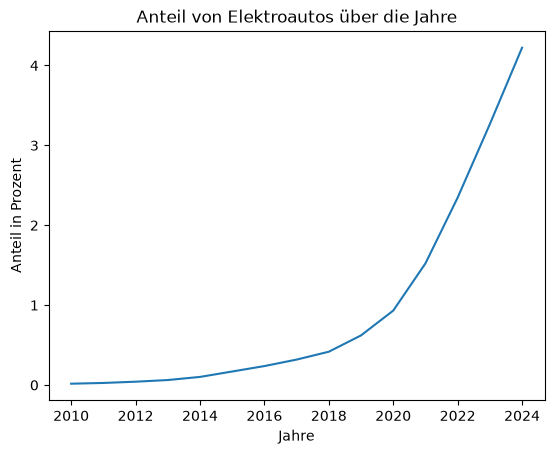

In [54]:
anteil_elektro = anzahl_elektro / anzahl_personenwagen * 100
plt.figure()
anteil_elektro.plot()
plt.xlabel('Jahre')
plt.ylabel('Anteil in Prozent')
plt.title('Anteil von Elektroautos über die Jahre')
plt.show()

Der Anteil reiner Elektroautos am Personenwagenbestand war bis etwa 2018 fast null und ist seither stark gewachsen: von 0,02 % (2010) auf 4,2 % (2024). Weil der Anteil 2010 so klein ist, werden Unterschiede zwischen den Gemeinden vor allem in den letzten Jahren messbar sein.